# Week 3 - Linear Regression 3 (Subset Selection, PCR, and PLSR)
## Dataset: FEMA NFIP Claims

This week covers three ways to handle a long list of possible features in linear regression. Forward and backward selection search for a smaller subset of the original features. Principal component regression (PCR) and partial least squares regression (PLSR) keep every feature but compress them into a few new components and regress on those instead.

The setup continues from the Week 1 NFIP notebook. The target is the log of the building payout for 2017 claims that paid something, and no damage or payout fields are used as features. This time the candidate list is wider, 31 features in all, including several policy fields that Week 1 did not use, such as contents coverage, the building's property value, the number of units, whether the policy covers a condo association, the basement or crawlspace type, and whether an elevation certificate is on file. The questions are how many of these are worth keeping, and whether compressing them works better than choosing among them.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

warnings.filterwarnings('ignore', category=FutureWarning)

df_raw = pd.read_csv('FimaNfipClaimsV2.csv', low_memory=False)
df = df_raw[(df_raw['yearOfLoss'] == 2017) & (df_raw['amountPaidOnBuildingClaim'] > 0)].copy()
print('2017 claims with a positive building payout:', len(df))

2017 claims with a positive building payout: 110352


### Candidate features

The 31 candidates fall into five groups, printed below. Water depth is capped at 15 and its centered square is included, since Week 1 showed the depth effect is curved. Dollar amounts and counts are on a log scale. Categorical fields are one-hot encoded with a baseline left out, which is Hurricane Harvey for the storm, rainfall accumulation for the cause of damage, A zones for the flood zone, and no basement for the basement type. About half of claims have no basement type recorded, so `basementMissing` gets its own indicator instead of dropping those rows.

Some of these candidates overlap heavily, and the heatmap after the next cell shows where. Replacement cost and property value are close to the same number (correlation 0.94), depth and its square move together (0.85), construction year tracks the post-FIRM indicator (0.75), and longitude tracks the Irma indicator (0.74), since Irma claims are mostly in Florida. Overlap like this is what makes the choice of features matter.

In [2]:
df['constructionYear'] = pd.to_datetime(df['originalConstructionDate'], errors='coerce').dt.year
needed = ['waterDepth', 'buildingReplacementCost', 'totalBuildingInsuranceCoverage',
          'numberOfFloorsInTheInsuredBuilding', 'elevatedBuildingIndicator', 'primaryResidenceIndicator',
          'constructionYear', 'latitude', 'longitude', 'postFIRMConstructionIndicator',
          'totalContentsInsuranceCoverage', 'numberOfUnits', 'policyCount']
data = df.dropna(subset=needed).copy()
data = data[data['constructionYear'].between(1800, 2017)].reset_index(drop=True)
y = np.log10(data['amountPaidOnBuildingClaim']).values

X = pd.DataFrame(index=data.index)
X['depth'] = data['waterDepth'].clip(-2, 15)
X['depthSquared'] = (X['depth'] - X['depth'].mean()) ** 2
X['logReplacementCost'] = np.log10(data['buildingReplacementCost'].clip(lower=1))
X['logPropertyValue'] = np.log10(data['buildingPropertyValue'].fillna(data['buildingReplacementCost']).clip(lower=1))
X['logBuildingCoverage'] = np.log10(data['totalBuildingInsuranceCoverage'].clip(lower=1))
X['logContentsCoverage'] = np.log10(data['totalContentsInsuranceCoverage'] + 1)
X['floors'] = data['numberOfFloorsInTheInsuredBuilding']
X['constructionYear'] = data['constructionYear']
X['latitude'] = data['latitude']
X['longitude'] = data['longitude']
X['logUnits'] = np.log10(data['numberOfUnits'] + 1)
X['logPolicyCount'] = np.log10(data['policyCount'])
for col in ['elevatedBuildingIndicator', 'primaryResidenceIndicator', 'postFIRMConstructionIndicator',
            'rentalPropertyIndicator', 'smallBusinessIndicatorBuilding']:
    X[col] = data[col].astype(float)
X['replacementCostBasis'] = (data['replacementCostBasis'] == 'R').astype(float)
X['condoPolicy'] = (data['condominiumCoverageTypeCode'].fillna('N') != 'N').astype(float)
X['elevationCertificate'] = data['elevationCertificateIndicator'].notna().astype(float)
zone = data['ratedFloodZone'].astype(str).str.upper().str[0]
X['zoneV'] = (zone == 'V').astype(float)
X['zoneX'] = (~zone.isin(['A', 'V'])).astype(float)
X['stormIrma'] = (data['floodEvent'] == 'Hurricane Irma').astype(float)
X['stormOther'] = (~data['floodEvent'].isin(['Hurricane Harvey', 'Hurricane Irma'])).astype(float)
cause = data['causeOfDamage'].astype(str)
X['causeRiverOverflow'] = (cause == '2').astype(float)
X['causeTidal'] = (cause == '1').astype(float)
X['causeOther'] = (~cause.isin(['1', '2', '4'])).astype(float)
basement = data['basementEnclosureCrawlspaceType']
X['basementFinished'] = (basement == 1).astype(float)
X['basementUnfinished'] = (basement == 2).astype(float)
X['crawlspace'] = (basement == 4).astype(float)
X['basementMissing'] = basement.isna().astype(float)

print('Claims used:', len(data), '| candidate features:', X.shape[1])
print()
groups = {'Water': ['depth', 'depthSquared'],
          'Value and coverage': ['logReplacementCost', 'logPropertyValue', 'logBuildingCoverage', 'logContentsCoverage'],
          'Building': ['floors', 'constructionYear', 'elevatedBuildingIndicator', 'postFIRMConstructionIndicator',
                       'basementFinished', 'basementUnfinished', 'crawlspace', 'basementMissing'],
          'Policy': ['primaryResidenceIndicator', 'rentalPropertyIndicator', 'smallBusinessIndicatorBuilding',
                     'replacementCostBasis', 'condoPolicy', 'elevationCertificate', 'logUnits', 'logPolicyCount'],
          'Location and flood': ['latitude', 'longitude', 'zoneV', 'zoneX', 'stormIrma', 'stormOther',
                                 'causeRiverOverflow', 'causeTidal', 'causeOther']}
for g, cols in groups.items():
    print(f'{g:20s} {", ".join(cols)}')
assert sum(len(c) for c in groups.values()) == X.shape[1]

Claims used: 100624 | candidate features: 31

Water                depth, depthSquared
Value and coverage   logReplacementCost, logPropertyValue, logBuildingCoverage, logContentsCoverage
Building             floors, constructionYear, elevatedBuildingIndicator, postFIRMConstructionIndicator, basementFinished, basementUnfinished, crawlspace, basementMissing
Policy               primaryResidenceIndicator, rentalPropertyIndicator, smallBusinessIndicatorBuilding, replacementCostBasis, condoPolicy, elevationCertificate, logUnits, logPolicyCount
Location and flood   latitude, longitude, zoneV, zoneX, stormIrma, stormOther, causeRiverOverflow, causeTidal, causeOther


Most correlated pairs of candidate features:
                  level_0                       level_1     r
       logReplacementCost              logPropertyValue 0.939
                    depth                  depthSquared 0.851
         constructionYear postFIRMConstructionIndicator 0.750
                longitude                     stormIrma 0.736
           logPolicyCount                   condoPolicy 0.657
                 logUnits                logPolicyCount 0.606
                 latitude                    stormOther 0.569
primaryResidenceIndicator          replacementCostBasis 0.547


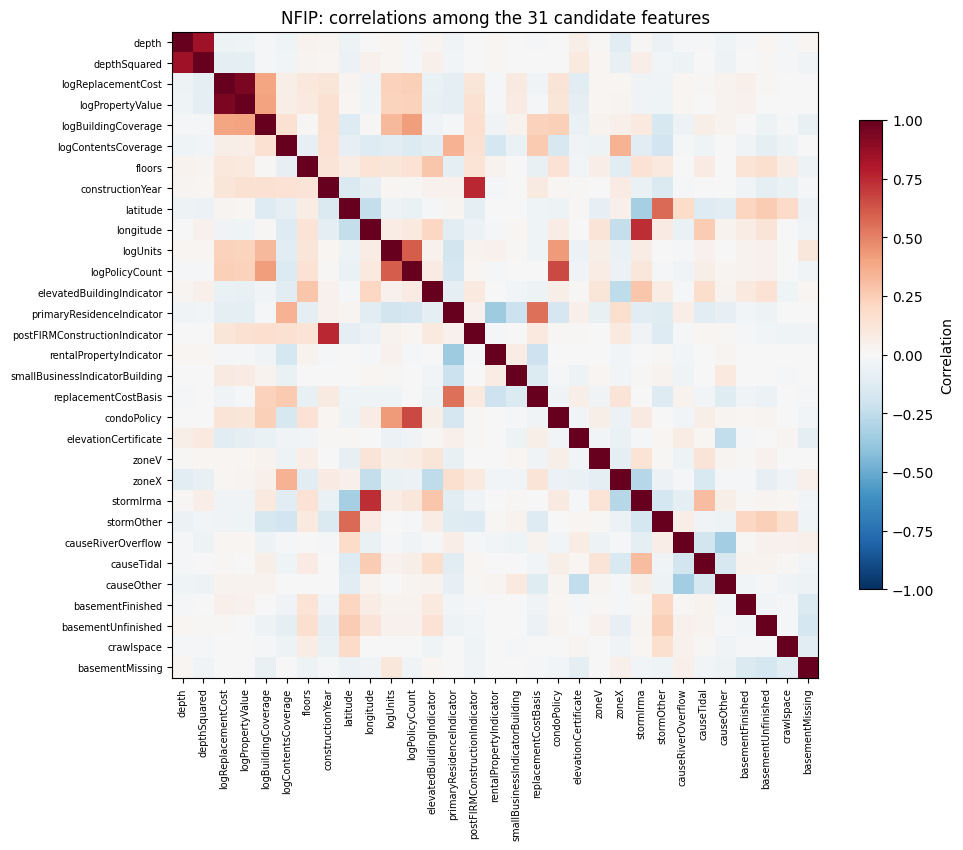

In [3]:
corr = X.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('r').reset_index().assign(abs_r=lambda t: t['r'].abs()).sort_values('abs_r', ascending=False))
print('Most correlated pairs of candidate features:')
print(pairs.head(8)[['level_0', 'level_1', 'r']].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7, label='Correlation')
ax.set_title('NFIP: correlations among the 31 candidate features')
plt.tight_layout()
plt.show()

In [4]:
train_idx, test_idx = train_test_split(np.arange(len(data)), test_size=0.25, random_state=0)
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]
kfold = KFold(n_splits=5, shuffle=True, random_state=0)
print('Training claims:', len(train_idx), '| test claims:', len(test_idx))


def cv_scores(cols):
    return cross_val_score(LinearRegression(), X_train[cols], y_train, cv=kfold, scoring='r2')

Training claims: 75468 | test claims: 25156


### Forward selection and backward elimination

Forward selection starts with no features and, at each step, adds the one that raises 5-fold cross-validated R-squared the most. Backward elimination starts with all 31 and removes the one whose removal hurts the least. Both are greedy searches, so neither is guaranteed to find the best possible subset, but trying all $2^{31}$ (about 2 billion) subsets is not practical. All scores are computed on the training set only.

In [5]:
t0 = time.time()
selected, remaining, forward = [], list(X.columns), []
while remaining:
    trial = {c: cv_scores(selected + [c]) for c in remaining}
    best = max(trial, key=lambda c: trial[c].mean())
    selected.append(best)
    remaining.remove(best)
    forward.append({'Step': len(selected), 'Added': best, 'CV R2': trial[best].mean(),
                    'CV SE': trial[best].std() / np.sqrt(5)})
forward = pd.DataFrame(forward)
print(f'Forward selection took {time.time() - t0:.0f} seconds')
print(forward[['Step', 'Added', 'CV R2']].head(15).round(4).to_string(index=False))

Forward selection took 75 seconds
 Step                         Added  CV R2
    1     elevatedBuildingIndicator 0.1136
    2                    stormOther 0.1652
    3                     stormIrma 0.2133
    4              logPropertyValue 0.2586
    5                         depth 0.2932
    6                  depthSquared 0.3198
    7           logBuildingCoverage 0.3311
    8 postFIRMConstructionIndicator 0.3366
    9               basementMissing 0.3405
   10            causeRiverOverflow 0.3435
   11              basementFinished 0.3458
   12            basementUnfinished 0.3483
   13                         zoneX 0.3501
   14          replacementCostBasis 0.3510
   15                   condoPolicy 0.3516


In [6]:
t0 = time.time()
current = list(X.columns)
backward = [{'Features left': len(current), 'Removed': '(none)', 'CV R2': cv_scores(current).mean()}]
while len(current) > 1:
    trial = {c: cv_scores([f for f in current if f != c]) for c in current}
    worst = max(trial, key=lambda c: trial[c].mean())
    current.remove(worst)
    backward.append({'Features left': len(current), 'Removed': worst, 'CV R2': trial[worst].mean()})
backward = pd.DataFrame(backward)
print(f'Backward elimination took {time.time() - t0:.0f} seconds')
print(backward.head(12).round(4).to_string(index=False))

# The k features kept by backward elimination, read off its removal order
kept_backward = {k: set(backward['Removed'].iloc[len(backward) - k + 1:]) | set(current) for k in range(1, X.shape[1] + 1)}
agree = [k for k in range(1, X.shape[1] + 1) if kept_backward[k] == set(forward['Added'].head(k))]
print()
print(f'Sizes where forward and backward pick exactly the same features: {len(agree)} of {X.shape[1]}')

Backward elimination took 164 seconds
 Features left                        Removed  CV R2
            31                         (none) 0.3543
            30                          zoneV 0.3543
            29 smallBusinessIndicatorBuilding 0.3544
            28           elevationCertificate 0.3544
            27      primaryResidenceIndicator 0.3544
            26                     causeTidal 0.3544
            25               constructionYear 0.3544
            24            logContentsCoverage 0.3543
            23                       latitude 0.3543
            22                      longitude 0.3542
            21                     causeOther 0.3541
            20                 logPolicyCount 0.3539

Sizes where forward and backward pick exactly the same features: 28 of 31


Best CV R2: 0.3544 with 27 features | one standard error: 0.0016
Smallest model within one standard error of the best: 17 features
Chosen features: ['elevatedBuildingIndicator', 'stormOther', 'stormIrma', 'logPropertyValue', 'depth', 'depthSquared', 'logBuildingCoverage', 'postFIRMConstructionIndicator', 'basementMissing', 'causeRiverOverflow', 'basementFinished', 'basementUnfinished', 'zoneX', 'replacementCostBasis', 'condoPolicy', 'crawlspace', 'floors']



scikit-learn's SequentialFeatureSelector picks the same set: True


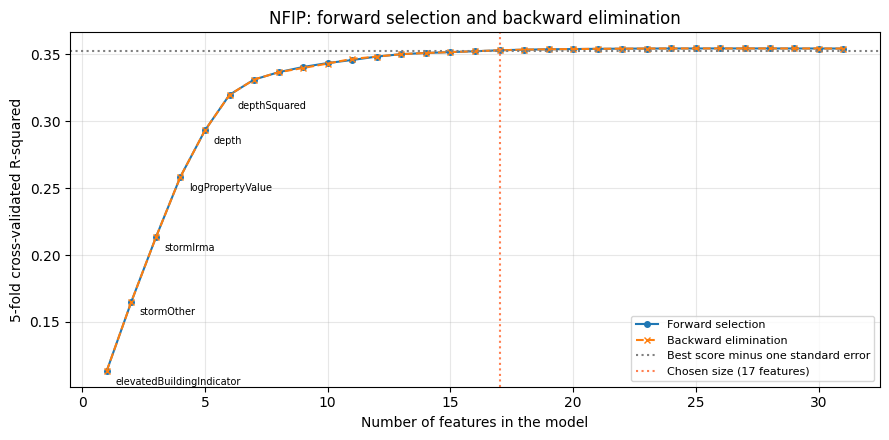

In [7]:
best_row = forward.loc[forward['CV R2'].idxmax()]
threshold = best_row['CV R2'] - best_row['CV SE']
k_1se = int(forward.loc[forward['CV R2'] >= threshold, 'Step'].min())
print(f"Best CV R2: {best_row['CV R2']:.4f} with {int(best_row['Step'])} features | one standard error: {best_row['CV SE']:.4f}")
print(f'Smallest model within one standard error of the best: {k_1se} features')
chosen = list(forward['Added'].head(k_1se))
print('Chosen features:', chosen)

sfs = SequentialFeatureSelector(LinearRegression(), n_features_to_select=k_1se, direction='forward',
                                scoring='r2', cv=kfold, n_jobs=-1).fit(X_train, y_train)
print()
print("scikit-learn's SequentialFeatureSelector picks the same set:",
      set(X.columns[sfs.get_support()]) == set(chosen))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(forward['Step'], forward['CV R2'], marker='o', markersize=4, label='Forward selection')
ax.plot(backward['Features left'], backward['CV R2'], marker='x', markersize=5, linestyle='--',
        label='Backward elimination')
ax.axhline(threshold, color='gray', linestyle=':', label='Best score minus one standard error')
ax.axvline(k_1se, color='coral', linestyle=':', label=f'Chosen size ({k_1se} features)')
for _, r in forward.head(6).iterrows():
    ax.annotate(r['Added'], (r['Step'], r['CV R2']), textcoords='offset points', xytext=(6, -10), fontsize=7)
ax.set_xlabel('Number of features in the model')
ax.set_ylabel('5-fold cross-validated R-squared')
ax.set_title('NFIP: forward selection and backward elimination')
ax.legend(fontsize=8, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Forward selection picks the elevated indicator first (CV R-squared 0.114), then the two storm indicators (0.213 after three steps), property value, water depth, and depth squared. Those six features reach 0.320, which is 90% of what all 31 features reach (0.354). After 13 features, each new one adds less than 0.001.

Forward and backward selection agree almost completely. They pick exactly the same set at 28 of the 31 possible sizes, and the curves in the plot lie on top of each other. The features backward elimination removes first (zone V, small business, elevation certificate, primary residence, tidal cause, construction year) are the ones forward selection adds last. With more than 75,000 claims, the ranking of features is stable enough that the direction of the search does not matter much.

The best CV score is 0.3544 with 27 features, but the curve is so flat that the one-standard-error rule picks 17 features, the smallest model within one standard error (0.0016) of the best. scikit-learn's `SequentialFeatureSelector` returns the same 17. Several features from Week 1 are not among them, including latitude, longitude, construction year, and primary residence. Each of those overlaps with something already in the model, such as the storm indicators for location or the post-FIRM indicator for building age.

### Principal component regression and partial least squares

PCR standardizes the 31 features, finds the principal components (the directions of greatest variance in the features), and regresses the log payout on the first few. PLSR also builds components, but it chooses each one to have the highest covariance with the target, not the highest variance in the features. The next cell sweeps both from 1 to 31 components and then looks at what the first components are made of.

Component sweep took 109 seconds
 Components  PCR CV R2  PLSR CV R2
          1     0.0003      0.2722
          2     0.1214      0.3129
          3     0.1227      0.3350
          4     0.1280      0.3440
          5     0.1954      0.3497
          6     0.2233      0.3532
          8     0.2583      0.3541
         10     0.2603      0.3543
         15     0.2662      0.3543
         20     0.2932      0.3543
         25     0.3057      0.3543
         28     0.3057      0.3543
         29     0.3247      0.3543
         30     0.3541      0.3543
         31     0.3543      0.3543



Components needed for 80% / 90% of the variance in X: 17 / 22
Components chosen by the one-standard-error rule: PCR 30, PLSR 6


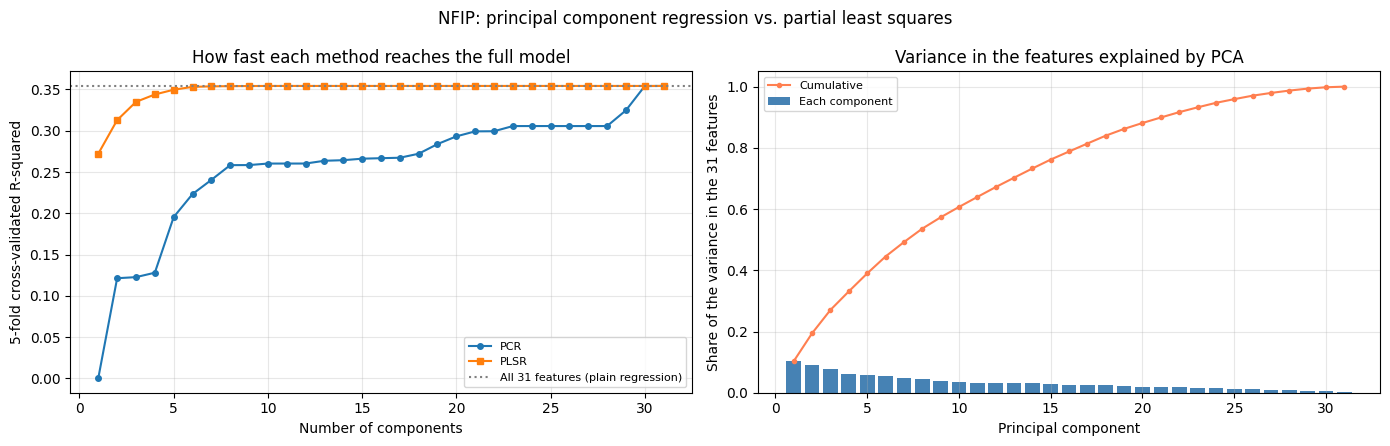

In [8]:
n_feat = X.shape[1]
comp_range = list(range(1, n_feat + 1))
pcr_rows = []
t0 = time.time()
for n in comp_range:
    pcr = make_pipeline(StandardScaler(), PCA(n_components=n), LinearRegression())
    pls = PLSRegression(n_components=n, scale=True)
    s_pcr = cross_val_score(pcr, X_train, y_train, cv=kfold, scoring='r2')
    s_pls = cross_val_score(pls, X_train, y_train, cv=kfold, scoring='r2')
    pcr_rows.append({'Components': n, 'PCR CV R2': s_pcr.mean(), 'PCR SE': s_pcr.std() / np.sqrt(5),
                     'PLSR CV R2': s_pls.mean(), 'PLSR SE': s_pls.std() / np.sqrt(5)})
comps = pd.DataFrame(pcr_rows)
print(f'Component sweep took {time.time() - t0:.0f} seconds')
print(comps[comps['Components'].isin([1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 25, 28, 29, 30, 31])]
      [['Components', 'PCR CV R2', 'PLSR CV R2']].round(4).to_string(index=False))

pca = PCA().fit(StandardScaler().fit_transform(X_train))
cum_var = np.cumsum(pca.explained_variance_ratio_)
print()
print('Components needed for 80% / 90% of the variance in X:',
      int(np.searchsorted(cum_var, 0.8) + 1), '/', int(np.searchsorted(cum_var, 0.9) + 1))


def pick_1se(score_col, se_col):
    best = comps.loc[comps[score_col].idxmax()]
    return int(comps.loc[comps[score_col] >= best[score_col] - best[se_col], 'Components'].min())


k_pcr, k_pls = pick_1se('PCR CV R2', 'PCR SE'), pick_1se('PLSR CV R2', 'PLSR SE')
print(f'Components chosen by the one-standard-error rule: PCR {k_pcr}, PLSR {k_pls}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(comps['Components'], comps['PCR CV R2'], marker='o', markersize=4, label='PCR')
axes[0].plot(comps['Components'], comps['PLSR CV R2'], marker='s', markersize=4, label='PLSR')
axes[0].axhline(forward['CV R2'].iloc[-1], color='gray', linestyle=':', label='All 31 features (plain regression)')
axes[0].set_xlabel('Number of components')
axes[0].set_ylabel('5-fold cross-validated R-squared')
axes[0].set_title('How fast each method reaches the full model')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
axes[1].bar(range(1, n_feat + 1), pca.explained_variance_ratio_, color='steelblue', label='Each component')
axes[1].plot(range(1, n_feat + 1), cum_var, color='coral', marker='o', markersize=3, label='Cumulative')
axes[1].set_xlabel('Principal component')
axes[1].set_ylabel('Share of the variance in the 31 features')
axes[1].set_title('Variance in the features explained by PCA')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
fig.suptitle('NFIP: principal component regression vs. partial least squares')
plt.tight_layout()
plt.show()

In [9]:
Z_train = StandardScaler().fit_transform(X_train)
pc_scores = pca.transform(Z_train)
corr_y = [np.corrcoef(pc_scores[:, i], y_train)[0, 1] for i in range(n_feat)]
print('Correlation of each of the first 8 principal components with log payout:')
print(pd.Series(corr_y[:8], index=[f'PC{i + 1}' for i in range(8)]).round(3).to_string())
best_pc = int(np.argmax(np.abs(corr_y)))
print(f'Most correlated component: PC{best_pc + 1} (r = {corr_y[best_pc]:.3f})')

pls1 = PLSRegression(n_components=1, scale=True).fit(X_train, y_train)
loadings = pd.DataFrame({'PC1 loading': pca.components_[0], 'PC2 loading': pca.components_[1],
                         'PLS component 1 weight': pls1.x_weights_[:, 0]}, index=X.columns)
print()
print('Largest loadings on the first two principal components and weights on the first PLS component:')
for col in loadings.columns:
    top = loadings[col].abs().sort_values(ascending=False).head(5).index
    print(f'{col:24s}', ', '.join(f'{f} ({loadings.loc[f, col]:+.2f})' for f in top))

Correlation of each of the first 8 principal components with log payout:
PC1   -0.021
PC2    0.348
PC3    0.037
PC4    0.073
PC5   -0.260
PC6   -0.167
PC7    0.131
PC8   -0.134
Most correlated component: PC2 (r = 0.348)

Largest loadings on the first two principal components and weights on the first PLS component:
PC1 loading              logPolicyCount (+0.39), logUnits (+0.34), condoPolicy (+0.32), logReplacementCost (+0.29), logPropertyValue (+0.28)
PC2 loading              logContentsCoverage (+0.31), logPropertyValue (+0.30), logReplacementCost (+0.29), logBuildingCoverage (+0.29), constructionYear (+0.28)
PLS component 1 weight   elevatedBuildingIndicator (+0.43), stormIrma (+0.32), logPropertyValue (-0.32), stormOther (+0.32), longitude (+0.31)


### Final evaluation on the held-out test set

Test claims: 25156
                             Model  Train R2  Test R2  Test RMSE (log10)
All 31 features (plain regression)    0.3550   0.3597             0.5046
    Forward selection, 17 features    0.3534   0.3590             0.5049
                PCR, 30 components    0.3548   0.3589             0.5049
                 PCR, 5 components    0.1956   0.2026             0.5631
                PLSR, 6 components    0.3539   0.3587             0.5050


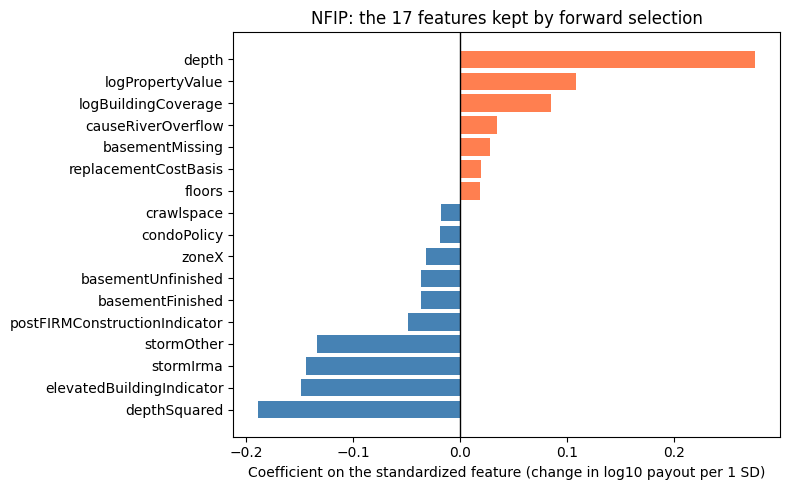

In [10]:
models = {
    'All 31 features (plain regression)': (list(X.columns), LinearRegression()),
    f'Forward selection, {k_1se} features': (chosen, LinearRegression()),
    f'PCR, {k_pcr} components': (list(X.columns), make_pipeline(StandardScaler(), PCA(k_pcr), LinearRegression())),
    'PCR, 5 components': (list(X.columns), make_pipeline(StandardScaler(), PCA(5), LinearRegression())),
    f'PLSR, {k_pls} components': (list(X.columns), PLSRegression(k_pls, scale=True)),
}
rows = []
for name, (cols, model) in models.items():
    model.fit(X_train[cols], y_train)
    pred_tr = np.ravel(model.predict(X_train[cols]))
    pred_te = np.ravel(model.predict(X_test[cols]))
    rows.append({'Model': name, 'Train R2': r2_score(y_train, pred_tr), 'Test R2': r2_score(y_test, pred_te),
                 'Test RMSE (log10)': mean_squared_error(y_test, pred_te) ** 0.5})
final = pd.DataFrame(rows)
print('Test claims:', len(test_idx))
print(final.round(4).to_string(index=False))

sel_model = LinearRegression().fit(StandardScaler().fit_transform(X_train[chosen]), y_train)
coef = pd.Series(sel_model.coef_, index=chosen).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coef.index, coef.values, color=np.where(coef.values > 0, 'coral', 'steelblue'))
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Coefficient on the standardized feature (change in log10 payout per 1 SD)')
ax.set_title(f'NFIP: the {k_1se} features kept by forward selection')
plt.tight_layout()
plt.show()

The difference between the two methods is large. PLSR's first component alone reaches a CV R-squared of 0.272, and 6 components reach 0.353, within 0.001 of the full model. PCR's first component explains nothing (0.0003), 5 components reach 0.195, and it needs 30 of the 31 components to catch up.

The loadings explain why. The first principal component is mostly the policy count, number of units, condo indicator, and building value, so it separates large multi-unit buildings from single homes. That is the biggest source of variation among the features, but it is almost uncorrelated with the payout (r = -0.02). The second component, a building value and coverage direction, is the one that matters (r = 0.35). The elevated indicator and the storm indicators, which forward selection found first, are not what the leading principal components are built around. The first PLS component goes straight to the features that matter for the payout, the elevated indicator, the storm indicators, property value, and longitude. (The signs of a component's weights only show which features move together, since the whole component can be flipped.)

On the 25,156 test claims all the full-strength models score the same. The plain regression with 31 features reaches a test R-squared of 0.360, forward selection with 17 features 0.359, PCR with 30 components 0.359, and PLSR with 6 components 0.359. PCR cut to 5 components drops to 0.203. Training and test scores are within 0.01 of each other for every model.

## Discussion

### Overfitting

None of these models overfit, and the reason is the ratio of claims to features. With 75,468 training claims and at most 31 features, every model's training R-squared is within 0.01 of its test R-squared. The selection curves show it too. Adding features never makes the cross-validated score worse in any meaningful way, it only stops making it better. That is a sharp contrast with the Storm Events notebook, where the full model scores worse than a selected subset on unseen storms.

What the three methods offer here is simplicity at no cost. Forward selection drops 14 of the 31 features, and PLSR compresses the 31 into 6 components, without losing any test accuracy. Every choice was made by cross-validation on the training set, and the test set was used once at the end. The CV score of a selected model is slightly optimistic, because the same folds chose the features and scored them, which is one more reason for the final test check.

### Metrics and hyperparameter tuning

R-squared on the log payout was the main metric, with RMSE in log10 units on the test set. The settings tuned were the number of features for subset selection and the number of components for PCR and PLSR. For all three, the one-standard-error rule chose the final value. It takes the simplest model whose CV score is within one standard error of the best, on the reasoning that a difference smaller than the noise between folds is not worth extra complexity. It picked 17 features, 6 PLSR components, and 30 PCR components. Fewer features or components mean a model that is easier to explain and less likely to fit noise.

### Expected or unexpected

I expected PLSR to need fewer components than PCR, and it did (6 against 30), but I did not expect PCR's first component to be useless. The largest direction of variation among the features is about multi-unit and condo policies, which matters for underwriting but not for how big a single building payout is. That is a clear example of why unsupervised compression can throw away the signal.

I was also surprised by which features forward selection did not need. Latitude, longitude, and construction year looked important in earlier notebooks, but once the storm indicators and the post-FIRM indicator are in the model they add almost nothing. The new policy fields helped a little. Property value replaced replacement cost as the preferred value measure, and the basement indicators entered between steps 9 and 12.

### How EDA helped

The correlation heatmap was the most useful EDA step. It showed which candidates were near-duplicates (property value and replacement cost, longitude and the Irma indicator), and those pairs explain the selection results, since forward selection keeps one of each pair and the other adds almost nothing. Earlier EDA set up the candidate list. The skew in payouts is why the target is logged, the Week 1 depth curve is why depth squared is a candidate, and the missing basement data, about half of all claims, is why missingness is its own indicator instead of a reason to drop rows.

### External sources

- scikit-learn User Guide, "Sequential Feature Selection": https://scikit-learn.org/stable/modules/feature_selection.html#sequential-feature-selection
- scikit-learn example, "Principal Component Regression vs Partial Least Squares Regression": https://scikit-learn.org/stable/auto_examples/cross_decomposition/plot_pcr_vs_pls.html
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, Chapter 6 ("Linear Model Selection and Regularization"), sections on subset selection, the one-standard-error rule, PCR, and partial least squares.

### Conclusions

For the NFIP claims, about 17 of the 31 candidate features carry all of the linear signal about payout size, and a regression on those 17 matches the full model on the test set (R-squared 0.359 against 0.360). The most important are whether the building is elevated, which storm caused the claim, the building's value, and water depth with its curve. PLSR reaches the same accuracy with 6 components, while PCR needs 30, because the biggest pattern among the features (multi-unit and condo policies) has nothing to do with payout size.

For the Capstone, this means a small, readable linear model is enough as a baseline for claim severity, and adding more policy fields is unlikely to help. The remaining variation has to come from new information, such as the land cover and property value data in the proposal, or from interactions and nonlinear models like those in Weeks 1 and 6.